# Titanic survival prediction

Logistic regression trained with gradient descent from scratch. The target is passenger survival: 0 = did not survive, 1 = survived.

## 1. Data
The supplied dataset contains 891 passengers. Ages, cabin values and two embarkation values are missing.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd


def stratified_split(y, seed=42):
    rng = np.random.default_rng(seed)
    train, test = [], []
    for label in [0, 1]:
        rows = rng.permutation(np.flatnonzero(y == label))
        count = int(np.ceil(0.2 * len(rows)))
        test.extend(rows[:count])
        train.extend(rows[count:])
    return np.sort(train), np.sort(test)


def stratified_folds(y, seed=42):
    rng = np.random.default_rng(seed)
    folds = np.empty(len(y), dtype=int)
    for label in [0, 1]:
        rows = rng.permutation(np.flatnonzero(y == label))
        folds[rows] = np.arange(len(rows)) % 5
    return folds


data = pd.read_csv('titanic.csv')
y = data.Survived.to_numpy(int)
assert set(y) == {0, 1} and data.PassengerId.is_unique
train, test = stratified_split(y)
assert not set(train) & set(test)
work = Path('tmp/titanic/results')
work.mkdir(parents=True, exist_ok=True)
print(f'{len(data)} passengers | {len(train)} training | {len(test)} test')
display(data[['Age', 'Cabin', 'Embarked']].isna().sum().rename('Missing'))
display(data[['Pclass', 'Sex', 'Age', 'Fare', 'Survived']].head(3))


891 passengers | 712 training | 179 test


Age         177
Cabin       687
Embarked      2
Name: Missing, dtype: int64

,Pclass,Sex,Age,Fare,Survived
0,3,male,22.0,7.2500,0
1,1,female,38.0,71.2833,1
2,3,female,26.0,7.9250,1


## 2. Preprocessing
Training medians and modes replace missing values. Categorical predictors are one-hot encoded and all encoded inputs are scaled using training statistics. IDs, raw names, tickets and cabin strings are excluded.

The enhanced features add title, family size, travelling-alone status, cabin presence, missing-age status, child status, log fare and a sex/class interaction.

In [2]:
def make_features(data, enhanced=False):
    frame = data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
    for column in ['Pclass', 'Sex', 'Embarked']:
        frame[column] = frame[column].astype('string').str.strip()
    if enhanced:
        title = data.Name.str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
        title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
        frame['Title'] = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
        frame['FamilySize'] = data.SibSp + data.Parch + 1
        frame['IsAlone'] = (frame.FamilySize == 1).astype(float)
        frame['CabinKnown'] = data.Cabin.notna().astype(float)
        frame['AgeMissing'] = data.Age.isna().astype(float)
        frame['IsChild'] = np.where(data.Age.notna(), data.Age < 16, np.nan)
        frame['LogFare'] = np.log1p(frame.pop('Fare'))
        frame['SexClass'] = frame.Sex + '_' + frame.Pclass
    return frame


def encode(frame, settings):
    table = frame.copy()
    for column, value in settings['medians'].items():
        table[column] = pd.to_numeric(table[column], errors='coerce').fillna(value)
    if 'IsChild' in table:
        table['IsChild'] = (table.Age < 16).astype(float)
    for column in settings['levels']:
        values = table[column].fillna(settings['modes'][column])
        table[column] = pd.Categorical(values, categories=settings['levels'][column])
    table = pd.get_dummies(table, columns=list(settings['levels']), drop_first=True, dtype=float)
    return np.ascontiguousarray(table.to_numpy(float)), list(table.columns)


def fit_preprocessor(frame):
    categories = [column for column in ['Pclass', 'Sex', 'Embarked', 'Title', 'SexClass'] if column in frame]
    settings = {'medians': {}, 'modes': {}, 'levels': {}}
    for column in frame:
        if column not in categories:
            settings['medians'][column] = float(frame[column].median())
    for column in categories:
        mode = str(frame[column].mode().iloc[0])
        settings['modes'][column] = mode
        settings['levels'][column] = sorted(frame[column].fillna(mode).unique())
    matrix, settings['columns'] = encode(frame, settings)
    settings['mean'] = matrix.mean(axis=0)
    settings['scale'] = matrix.std(axis=0)
    settings['scale'][settings['scale'] < 1e-12] = 1
    return settings


def transform(frame, settings):
    matrix, columns = encode(frame, settings)
    assert columns == settings['columns']
    return (matrix - settings['mean']) / settings['scale']



## 3. Logistic regression
A small class implements probabilities and predictions. Gradient descent minimizes regularized cross-entropy. Momentum accelerates the updates, and the intercept is unpenalized. The sigmoid and loss calculations remain stable for extreme scores.

In [3]:
class LogisticRegression:
    def __init__(self, alpha=1, threshold=0.5):
        self.alpha, self.threshold = alpha, threshold

    @staticmethod
    def sigmoid(scores):
        probability = np.empty_like(scores, dtype=float)
        positive = scores >= 0
        probability[positive] = 1 / (1 + np.exp(-scores[positive]))
        exponential = np.exp(scores[~positive])
        probability[~positive] = exponential / (1 + exponential)
        return probability

    def loss_gradient(self, design, y, weights):
        scores = design @ weights
        penalty = self.alpha * weights / len(y)
        penalty[0] = 0
        loss = np.mean(np.logaddexp(0, scores) - y*scores) + self.alpha*np.sum(weights[1:]**2)/(2*len(y))
        gradient = design.T @ (self.sigmoid(scores) - y) / len(y) + penalty
        return float(loss), gradient

    def fit(self, matrix, y):
        design = np.column_stack([np.ones(len(matrix)), matrix])
        rate = 1 / (0.25*np.linalg.eigvalsh(design.T @ design / len(y))[-1] + self.alpha/len(y))
        self.weights = np.zeros(design.shape[1])
        lookahead, time = self.weights.copy(), 1.0
        loss, _ = self.loss_gradient(design, y, self.weights)
        self.history = [{'iteration': 0, 'loss': loss}]
        for iteration in range(1, 25001):
            _, gradient = self.loss_gradient(design, y, lookahead)
            updated = lookahead - rate*gradient
            next_loss, next_gradient = self.loss_gradient(design, y, updated)
            if next_loss > loss + 1e-12:
                _, gradient = self.loss_gradient(design, y, self.weights)
                updated = self.weights - rate*gradient
                next_loss, next_gradient = self.loss_gradient(design, y, updated)
                time = 1.0
            next_time = (1 + np.sqrt(1 + 4*time*time)) / 2
            lookahead = updated + (time-1)/next_time*(updated-self.weights)
            self.weights, time, loss = updated, next_time, next_loss
            if iteration % 25 == 0:
                self.history.append({'iteration': iteration, 'loss': loss})
                self.gradient_norm = float(np.max(np.abs(next_gradient)))
                if self.gradient_norm <= 1e-7:
                    break
        if self.gradient_norm > 1e-7:
            raise RuntimeError('Gradient descent did not converge')
        self.iterations = iteration
        return self

    def predict_proba(self, matrix):
        design = np.column_stack([np.ones(len(matrix)), matrix])
        return self.sigmoid(design @ self.weights)

    def predict(self, matrix):
        return (self.predict_proba(matrix) >= self.threshold).astype(int)



## 4. Cross-validation
Five stratified folds are repeated three times. Basic and enhanced features are compared with penalties 0.1, 1 and 10, and thresholds 0.4, 0.5 and 0.6. Selection prioritizes pooled validation accuracy, then lower log loss and fewer features.

In [4]:
def roc_curve(y, probability):
    y, probability = np.asarray(y), np.asarray(probability)
    order = np.argsort(-probability, kind='stable')
    labels, scores = y[order], probability[order]
    ends = np.r_[np.flatnonzero(np.diff(scores)), len(scores)-1]
    tpr = np.r_[0, np.cumsum(labels == 1)[ends] / np.sum(y == 1)]
    fpr = np.r_[0, np.cumsum(labels == 0)[ends] / np.sum(y == 0)]
    return fpr, tpr


def metrics(y, probability, threshold=0.5):
    y, probability = np.asarray(y), np.asarray(probability)
    prediction = probability >= threshold
    tp = np.sum((y == 1) & prediction)
    tn = np.sum((y == 0) & ~prediction)
    fp = np.sum((y == 0) & prediction)
    fn = np.sum((y == 1) & ~prediction)
    precision, recall = tp/max(tp+fp, 1), tp/max(tp+fn, 1)
    fpr, tpr = roc_curve(y, probability)
    p = np.clip(probability, 1e-15, 1-1e-15)
    return {'Accuracy': float((tp+tn)/len(y)), 'Precision': float(precision),
            'Recall': float(recall), 'F1': float(2*precision*recall/max(precision+recall, 1e-15)),
            'Balanced accuracy': float((recall+tn/max(tn+fp, 1))/2),
            'ROC-AUC': float(np.trapezoid(tpr, fpr)),
            'Log loss': float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))}


In [5]:
alphas, thresholds = [0.1, 1, 10], [0.4, 0.5, 0.6]
oof = {(enhanced, alpha): np.full((3, len(train)), np.nan)
       for enhanced in [False, True] for alpha in alphas}
folds_by_repeat = [stratified_folds(y[train], seed=42+r) for r in range(3)]
convergence, feature_counts = [], {}
for enhanced in [False, True]:
    frame = make_features(data, enhanced)
    for repeat, folds in enumerate(folds_by_repeat):
        for fold in range(5):
            fitting, validation = train[folds != fold], train[folds == fold]
            assert not set(fitting) & set(validation)
            settings = fit_preprocessor(frame.iloc[fitting])
            X_fit, X_valid = transform(frame.iloc[fitting], settings), transform(frame.iloc[validation], settings)
            feature_counts[enhanced] = X_fit.shape[1]
            for alpha in alphas:
                model = LogisticRegression(alpha).fit(X_fit, y[fitting])
                oof[(enhanced, alpha)][repeat, folds == fold] = model.predict_proba(X_valid)
                convergence.append({'Enhanced': enhanced, 'Alpha': alpha, 'Repeat': repeat+1, 'Fold': fold,
                                    'Iterations': model.iterations, 'Gradient norm': model.gradient_norm})
    print(f"Completed {'enhanced' if enhanced else 'basic'} features")
rows = []
for (enhanced, alpha), probability in oof.items():
    assert np.isfinite(probability).all()
    for threshold in thresholds:
        rows.append({'Features': 'Enhanced' if enhanced else 'Basic', 'Enhanced': enhanced,
                     'Alpha': alpha, 'Threshold': threshold, 'Feature count': feature_counts[enhanced],
                     'Threshold distance': abs(threshold-0.5),
                     **metrics(np.tile(y[train], 3), probability.ravel(), threshold)})
comparison = pd.DataFrame(rows).sort_values(
    ['Accuracy', 'Log loss', 'Feature count', 'Threshold distance', 'Alpha'],
    ascending=[False, True, True, True, True], kind='stable').reset_index(drop=True)
best = comparison.iloc[0]
display(comparison[['Features', 'Alpha', 'Threshold', 'Accuracy', 'ROC-AUC', 'Log loss']].head(6).round(4))


Completed basic features


Completed enhanced features


,Features,Alpha,Threshold,Accuracy,ROC-AUC,Log loss
0,Enhanced,1.0,0.5,0.8333,0.8589,0.4225
1,Enhanced,10.0,0.5,0.8305,0.8610,0.4209
2,Enhanced,0.1,0.5,0.8277,0.8583,0.4262
3,Enhanced,10.0,0.6,0.8193,0.8610,0.4209
4,Enhanced,1.0,0.6,0.8188,0.8589,0.4225
5,Enhanced,0.1,0.6,0.8188,0.8583,0.4262


## 5. Evaluation
The chosen settings are fitted on all training passengers before evaluation on the reserved test passengers. Survivor precision, recall and F1 use survival as the positive class. All seven metrics are calculated from scratch.

In [6]:
enhanced, alpha, threshold = bool(best.Enhanced), float(best.Alpha), float(best.Threshold)
frame = make_features(data, enhanced)
settings = fit_preprocessor(frame.iloc[train])
model = LogisticRegression(alpha, threshold).fit(transform(frame.iloc[train], settings), y[train])
assert model.gradient_norm <= 1e-7
train_probability = model.predict_proba(transform(frame.iloc[train], settings))
test_probability = model.predict_proba(transform(frame.iloc[test], settings))
test_prediction = model.predict(transform(frame.iloc[test], settings))
cv_probability = oof[(enhanced, alpha)]
train_metrics = metrics(y[train], train_probability, threshold)
cv_metrics = metrics(np.tile(y[train], 3), cv_probability.ravel(), threshold)
test_metrics = metrics(y[test], test_probability, threshold)
baseline_metrics = metrics(y[test], np.full(len(test), y[train].mean()), 0.5)
metric_table = pd.DataFrame({'Train': train_metrics, 'Cross-validation': cv_metrics,
                             'Test': test_metrics, 'Majority baseline': baseline_metrics})
display(metric_table.round(4))
print(f'{best.Features} features | penalty {alpha:g} | threshold {threshold:g}')
print(f'Converged in {model.iterations} updates; gradient norm {model.gradient_norm:.2e}')


,Train,Cross-validation,Test,Majority baseline
Accuracy,0.8497,0.8333,0.8380,0.6145
Precision,0.8517,0.8247,0.8333,0.0000
Recall,0.7363,0.7179,0.7246,0.0000
F1,0.7898,0.7676,0.7752,0.0000
Balanced accuracy,0.8283,0.8115,0.8169,0.5000
ROC-AUC,0.8815,0.8589,0.8866,0.5000
Log loss,0.3892,0.4225,0.4183,0.6667


Enhanced features | penalty 1 | threshold 0.5
Converged in 300 updates; gradient norm 1.85e-08


## 6. Visualizations
The confusion matrix separates missed survivors from false survival predictions. The ROC curve describes discrimination across thresholds. Training loss describes optimization rather than test accuracy.

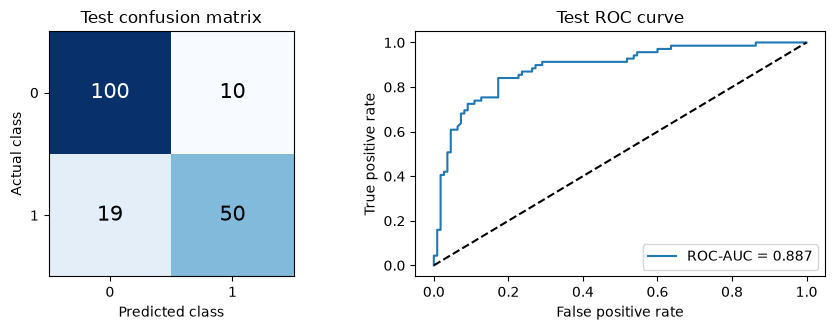

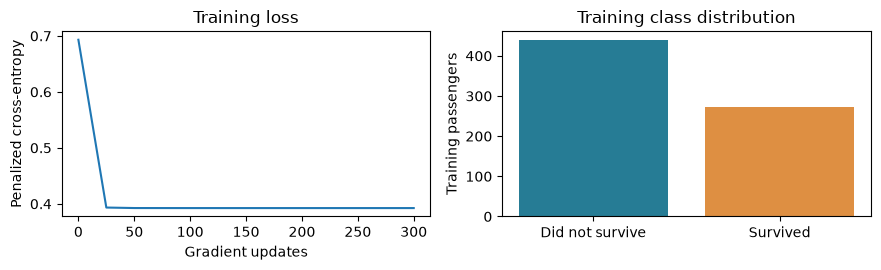

In [7]:
counts = np.array([[np.sum((y[test] == actual) & (test_prediction == predicted))
                    for predicted in [0, 1]] for actual in [0, 1]])
fpr, tpr = roc_curve(y[test], test_probability)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].imshow(counts, cmap='Blues')
for i in [0, 1]:
    for j in [0, 1]:
        axes[0].text(j, i, str(counts[i, j]), ha='center', va='center', fontsize=15,
                     color='white' if counts[i, j] > counts.max()/2 else 'black')
axes[0].set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicted class', ylabel='Actual class', title='Test confusion matrix')
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC curve')
axes[1].legend(loc='lower right')
fig.tight_layout()
fig.savefig(work/'test_diagnostics.png', dpi=160)
plt.show()
history = pd.DataFrame(model.history)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].plot(history.iteration, history.loss)
axes[0].set(xlabel='Gradient updates', ylabel='Penalized cross-entropy', title='Training loss')
axes[1].bar(['Did not survive', 'Survived'], np.bincount(y[train]), color=['#267c95', '#de8f42'])
axes[1].set(ylabel='Training passengers', title='Training class distribution')
fig.tight_layout()
fig.savefig(work/'training_diagnostics.png', dpi=160)
plt.show()


In [8]:
selected_fold_scores = [metrics(y[train][folds == fold], cv_probability[repeat, folds == fold], threshold)['Accuracy']
                        for repeat, folds in enumerate(folds_by_repeat) for fold in range(5)]
summary = {'features': str(best.Features), 'alpha': alpha, 'threshold': threshold,
           'n_train': len(train), 'n_test': len(test), 'encoded_features': len(settings['columns']),
           'iterations': model.iterations, 'gradient_norm': model.gradient_norm,
           'train_metrics': train_metrics, 'cv_metrics': cv_metrics, 'test_metrics': test_metrics,
           'baseline_metrics': baseline_metrics, 'confusion_matrix': counts.tolist(),
           'cv_fold_accuracy_std': float(np.std(selected_fold_scores, ddof=1)),
           'all_cv_fits_converged': all(row['Gradient norm'] <= 1e-7 for row in convergence)}
(work/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
comparison.to_csv(work/'model_comparison.csv', index=False)
metric_table.to_csv(work/'metrics.csv')
pd.DataFrame(convergence).to_csv(work/'convergence.csv', index=False)
pd.DataFrame({'PassengerId': data.iloc[test].PassengerId, 'Actual': y[test],
              'Probability': test_probability, 'Predicted': test_prediction}).to_csv(work/'test_predictions.csv', index=False)
splits = pd.DataFrame({'PassengerId': data.PassengerId, 'Split': np.where(np.isin(np.arange(len(data)), test), 'test', 'train')})
for repeat, folds in enumerate(folds_by_repeat, 1):
    splits[f'Repeat_{repeat}'] = -1
    splits.loc[train, f'Repeat_{repeat}'] = folds
splits.to_csv(work/'splits.csv', index=False)
assert np.isfinite(test_probability).all() and ((test_probability >= 0) & (test_probability <= 1)).all()
print(f"Test accuracy: {test_metrics['Accuracy']:.2%} | F1: {test_metrics['F1']:.4f} | ROC-AUC: {test_metrics['ROC-AUC']:.4f}")


Test accuracy: 83.80% | F1: 0.7752 | ROC-AUC: 0.8866


The test passengers remain separate from model and threshold selection. These results describe the supplied Titanic dataset. Shared families and tickets can make passenger-level splits optimistic for predicting entirely unseen travel groups.